In [52]:
import numpy as np 
import matplotlib.pyplot as plt 


## The Burgers' equation

$$ u_t = uu_x $$

And the modified equations

$$ u_t = u^p u_x, \quad p \in \mathbb{N} $$

And theirs spectral representations

$$ \hat{u_t} = ik \cdot \mathcal{F} \left( \mathcal{F}^{-1} \left( \hat{u} \right)^2 \right)

In [53]:
def _nonlinear_32(u_hat_in, k , N):
    """3/2-rule dealias computation of -F(u*u_x)"""
    M = int(np.ceil(1.5*N))
    if M%2 !=0:
        M+=1
        
    def pad(a_hat):
        a_pad = np.zeros(M, dtype=complex)
        half = N//2
        a_pad[:half] = a_hat[:half]
        a_pad[-half:] = a_hat[-half:]
        return a_pad*(M/N)
    
    u_pad = np.fft.ifft(pad(u_hat_in)).real
    ux_pad = np.fft.ifft(pad(1j * k * u_hat_in)).real
    nl_pad = u_pad * ux_pad

    nl_hat_pad = np.fft.fft(nl_pad)
    nl_hat = np.zeros(N, dtype=complex)
    half = N // 2
    nl_hat[:half] = nl_hat_pad[:half]
    nl_hat[-half:] = nl_hat_pad[-half:]
    nl_hat *= (N / M)

    return -nl_hat



In [54]:
def rk_spectral_burgers(u0, L, dt, dealias = '23', safety_margin = 1.0, save_every = 1):
    """
    Solving the inviscous Burgers' equation u_t + u*u_x = 0.
    Stopping at the breaking point t = t_s
    Using a pseudospectral method with RK4 time-stepping

    Args:
        u0 (array like): Initial conditial in the physical space (real-valued),  length N
        L (float): Length of the physical domain
        dt (float): Time step size
        dealias (str, optional):    '23' -> Truncating
                                    '32' -> zero-padding before multiplication
                                    Defaults to '23'.
        safetry_margin (float, optional): Margin for the breaking point t_s, t_target = margin*t_s. Defaults to 1                            
        save_every (int, optional): save t and u every n-th step
                                    
    Returns:
        u_out (array like): Solution in Physical space shape (1,N) # Might change
    """
    N =len(u0)
    dx = L/N
    k = np.fft.fftfreq(N,d=dx)*2*np.pi
    
    u0_hat = np.fft.fft(u0)
    u0_prime = np.fft.ifft(1j*k*u0_hat).real
    min_slope = np.min(u0_prime)
    
    if min_slope >= 0:
        raise ValueError(
            "min(u0') >= 0: No compressive region, characteristics never cross."
            "i.e. No finite shock time exist for the given initial condition."
        )
    t_s = -1/min_slope
    t_target = t_s * safety_margin
    
    
    if dealias == '23':
        k_max = np.max(np.abs(k))
        mask = (np.abs(k) < (2/3)*k_max)
    else: mask = None
    
    def nonlinear_rhs(u_hat_in,dealias='23', step_dt=None):
        """RHS = -F[u*u_x], pseudospectrally, with the given dealiasing"""
        if dealias == '32':
            return _nonlinear_32(u_hat_in, k , N)
        u = np.fft.ifft(u_hat_in).real
        ux = np.fft.ifft(1j * k*u_hat_in).real
        nl_hat = np.fft.fft(u * ux)
        if dealias == '23':
            nl_hat*=mask
            
        return -nl_hat
            
    def rk4_step(u_hat_in,h):
        k1 = nonlinear_rhs(u_hat_in)
        k2 = nonlinear_rhs(u_hat_in + 0.5*h*k1)
        k3 = nonlinear_rhs(u_hat_in + 0.5*h*k2)
        k4 = nonlinear_rhs(u_hat_in + h*k3)
        return u_hat_in + (h/6.0)*(k1 + 2*k2 + 2*k3 + k4)
    
    u_hat = u0_hat.copy()
    t_list = [0.0]
    u_list = [u0.copy()]
    
    t_curr = 0.0
    step_count = 0
    while t_curr < t_target - 1e-14:
        h = min(dt, t_target - t_curr) #Truncate final step
        u_hat = rk4_step(u_hat,h)
        t_curr += h 
        step_count += 1
        
        if step_count % save_every == 0 or t_curr >= t_target - 1e-14:
            t_list.append(t_curr)
            u_list.append(np.fft.ifft(u_hat).real)
            
    return np.array(t_list), np.array(u_list), t_s

In [55]:
# Test
import numpy as np
import matplotlib.pyplot as plt

def plot_burgers_results(t, u_out, L, t_s, k=None, n_snapshots=6):
    """
    Diagnostic plots for the inviscid Burgers' solver.

    Parameters
    ----------
    t : array_like
        Times returned by spectral_inviscid_burgers_solver.
    u_out : array_like
        Solution array, shape (num_saved, N).
    L : float
        Domain length.
    t_s : float
        Shock formation time (for reference lines / titles).
    k : array_like or None
        Wavenumbers; if None, recomputed from N and L.
    n_snapshots : int
        Number of solution snapshots to overlay in the first plot.
    """
    N = u_out.shape[1]
    x = np.linspace(0, L, N, endpoint=False)
    if k is None:
        k = np.fft.fftfreq(N, d=L/N) * 2 * np.pi

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    # --- 1. Snapshots of u(x,t) at several times ---
    ax = axes[0]
    snap_idx = np.linspace(0, len(t)-1, n_snapshots).astype(int)
    colors = plt.cm.viridis(np.linspace(0, 0.9, n_snapshots))
    for i, idx in zip(range(n_snapshots), snap_idx):
        ax.plot(x, u_out[idx], color=colors[i], label=f"t={t[idx]:.3f}")
    ax.set_xlabel("x")
    ax.set_ylabel("u(x,t)")
    ax.set_title("Solution snapshots")
    ax.legend(fontsize=8, loc='best')

    # --- 2. Space-time heatmap ---
    ax = axes[1]
    extent = [0, L, t[0], t[-1]]
    im = ax.imshow(u_out, aspect='auto', origin='lower', extent=extent,
                    cmap='RdBu_r')
    ax.axhline(t_s, color='k', linestyle='--', linewidth=1, label=f"$t_s$={t_s:.3f}")
    ax.set_xlabel("x")
    ax.set_ylabel("t")
    ax.set_title("Space-time evolution")
    ax.legend(fontsize=8, loc='upper right')
    fig.colorbar(im, ax=ax, label="u")

    # --- 3. max|u_x(t)| blow-up diagnostic ---
    ax = axes[2]
    max_ux = np.array([
        np.max(np.abs(np.fft.ifft(1j * k * np.fft.fft(u_out[i])).real))
        for i in range(len(t))
    ])
    ax.plot(t, max_ux, 'o-', markersize=3)
    t_fine = np.linspace(0, t_s*0.98, 200)
    ax.plot(t_fine, 1.0/(t_s - t_fine), 'r--', alpha=0.5, label=r'$1/(t_s-t)$ (theory)')
    ax.axvline(t_s, color='k', linestyle='--', linewidth=1, label=f"$t_s$={t_s:.3f}")
    ax.set_xlabel("t")
    ax.set_ylabel(r"$\max_x |u_x(x,t)|$")
    ax.set_title("Gradient blow-up")
    ax.set_yscale('log')
    ax.legend(fontsize=8)
    

    plt.tight_layout()
    plt.show()

    return max_ux

Computed t_s = 1.000000


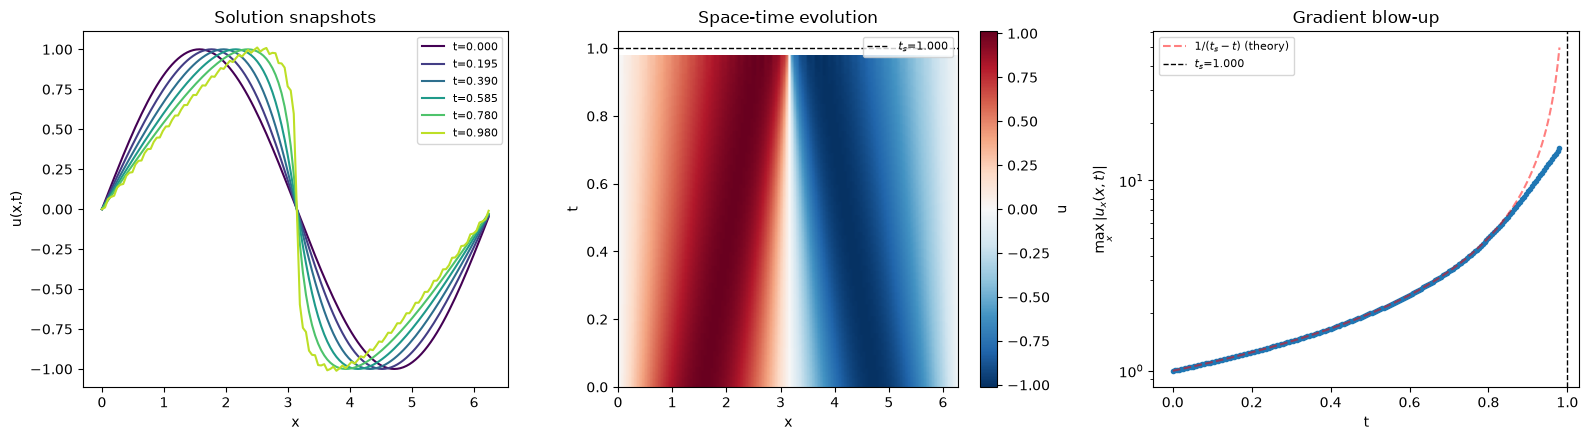

In [56]:
N = 128
L = 2 * np.pi
x = np.linspace(0, L, N, endpoint=False)
u0 = np.sin(x)

t, u_out, t_s = rk_spectral_burgers(
    u0, L, dt=0.001, dealias='23', save_every=5, safety_margin=0.98
)

print(f"Computed t_s = {t_s:.6f}")  # should be ~1.0 for sin(x)

max_ux = plot_burgers_results(t, u_out, L, t_s)